# Quantum Metal 54 — two-qubit cell (D5–Z3) of the ETH 17-qubit surface-code mock-up, for meshing (Quantcore PDK rebuild)

**What the chip is.** Qiskit Metal `docs/circuit-examples/F.Small-quantum-chips/54-Wallraff_TwoQubit_Cell_Mesh.ipynb`,
which calls `wallraff_17q.build_cell(("D5", "Z3"))` from `resources/wallraff_17q/` (the builder of notebook 53,
traced from micrographs of Krinner *et al.*, Nature 605, 669 (2022); "a mockup, not a mask"), © Qiskit Metal
contributors, Apache-2.0 (<https://github.com/qiskit-community/qiskit-metal>); spec
`docs/designs/metal/54_wallraff_cell.md`; the id is prefixed `m` (ids do not start with a digit). We distribute the
rebuild under GPL-3.0. Data qubit `D5` and auxiliary qubit `Z3`, two `StarQubit` transmons (a centre island with
five pads at 72°: four couplers and a readout pad), joined by their lattice coupler line, cropped to the qubits plus a
350 µm margin. The source meshes it with gmsh and solves its capacitance matrix with ElmerFEM; that matrix is the
reference here.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the builder's own options; the chip, the stack,
the junctions, the route, the netlist and the LOM are ours.

| | Qiskit Metal 54 | Quantcore PDK rebuild |
|---|---|---|
| chip | a 2309.2 × 700 µm cut-out (qubits + 350 µm), centred on (804.6, 0) µm, D5 at the origin | the 7.5 × 7.5 mm Quantcore die with the QCT frame; the cut-out is centred in it (`box=(−2595.4, −3400, 4904.6, 4100)`), so every coordinate stays the source's (+350, +350) µm |
| substrate | silicon (the Elmer model) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| pads | none | none (nothing for the pad rule to move) |
| junctions | none (electrostatics only) | Quantcore Nb/AlOx/Nb trilayer junction in each StarQubit, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF) |
| cheese | none (no GDS export; the source meshes the cut-out) | the PDK band (chip `cheese: "auto"`) |
| coupler | traced `PolylineCPW`, 8.5 / 5.5 µm, fillet 15 µm | a qcc `cpw` route on the same 31 points, same CPW and fillet |
| free pads | merged into `ground_plane` in the Elmer model | a snapped `metal:ShortToGround` on each (no geometry; it tells the LOM the pad is ground) |
| placement | as drawn | content centred in the die (already centred) |

**Kept exactly:** both `StarQubit`s with the builder's options (radius 160 µm, centre radius 53 µm, coupler /
readout gaps 13 / 6 µm, connector length 40 µm, 4 connectors) and pad rotations (D5: flux axis 0°, side +1; Z3:
side −1), the qubit positions (1609.2 µm apart) and the coupler line: the builder's traced `PolylineCPW` (31 points
after its simplification, 45 µm resampling and 40 µm pin leads) as waypoints, 8.5 / 5.5 µm CPW, fillet 15 µm.

**How this notebook goes.** First the **Design**: the cell is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die, the two StarQubits with their grounded free pads, the coupler line between
them, and then the whole chip (no pads, readouts or control lines: those segments say so in one sentence). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `m54_wallraff_cell.v1.ipynb`; both save the same
`m54_wallraff_cell.json`.

## Setup

The imports, the output folder, the Metal → Designer helper `P`, the builder's StarQubit options, pad rotations and coupler points, the source's Elmer capacitances, and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
X0, Y0 = 350, 350                                # Metal's cell: D5 at the origin, chip = qubits + 350 µm margin
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
STAR = dict(radius=160, center_radius=53, gap_couplers=13, gap_readout=6, connector_length=40, trap_offset=11,
            junc_h=53, number_of_connectors=4, resolution=16)
# pad rotations (Metal rotation_* = compass angle + 90), from wallraff_17q.pad_angles
ROT = {"D5": dict(rotation_cpl1=54, rotation_cpl2=198, rotation_cpl3=270, rotation_cpl4=342, rotation_rdout=126,
                  rotation_jj=90),
       "Z3": dict(rotation_cpl1=126, rotation_cpl2=198, rotation_cpl3=270, rotation_cpl4=342, rotation_rdout=54,
                  rotation_jj=90)}
# CPL_D5_Z3: the builder's PolylineCPW points (Metal µm, D5 at the origin), pin to pin
CPL = [(161.803, -117.557), (194.164, -141.068), (241.931, -158.748), (286.256, -154.887), (325.96, -132.643),
       (365.663, -110.4), (405.366, -88.157), (445.07, -65.914), (484.773, -43.67), (524.835, -22.131),
       (566.965, -5.701), (612.006, -0.019), (657.515, -0.101), (703.025, -0.183), (748.534, -0.265),
       (794.043, -0.347), (839.553, -0.429), (885.062, -0.511), (930.572, -0.593), (976.081, -0.675),
       (1021.591, -0.757), (1067.1, -0.839), (1111.078, -6.611), (1146.044, -33.885), (1173.559, -68.899),
       (1212.674, -79.346), (1248.118, -52.991), (1277.88, -19.456), (1318.218, -2.612), (1369.2, 0.0),
       (1409.2, 0.0)]
ELMER = {"D5": 167.02, "Z3": 168.07, "D5-cpl": 18.39, "Z3-cpl": 18.40, "D5-Z3": 0.06}  # source's Elmer C (fF)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 7.5 mm die gets the QCT frame round the small cut-out; there are no pads for the pad rule; both StarQubits get the PDK nominal trilayer junction; the free ground gets the PDK cheese band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). The source is a two-qubit cell cut out of a 17-qubit chip for meshing, so only segments 4 and 6 place
anything.

| segment | what is placed here |
|---|---|
| 1 | the 7.5 mm die with the QCT frame, centred on the 2.3 × 0.7 mm cut-out |
| 2–3 | nothing: a meshing cut-out has no bond pads and no feedline |
| 4 | the two StarQubits D5 and Z3 with their trilayer junctions, and the grounded free pads |
| 5 | nothing: no readout resonators in the cut-out |
| 6 | the coupling: the traced coupler line `CPL_D5_Z3` |
| 7 | nothing: no flux or drive lines |
| 8 | the whole chip: sim group, centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (optional: no free edge, no ID). The source's cut-out spans
(0, 0)–(2309.2, 700) µm here (`P(x, y)` = Metal + (350, 350)); the 7.5 mm die is centred on it.

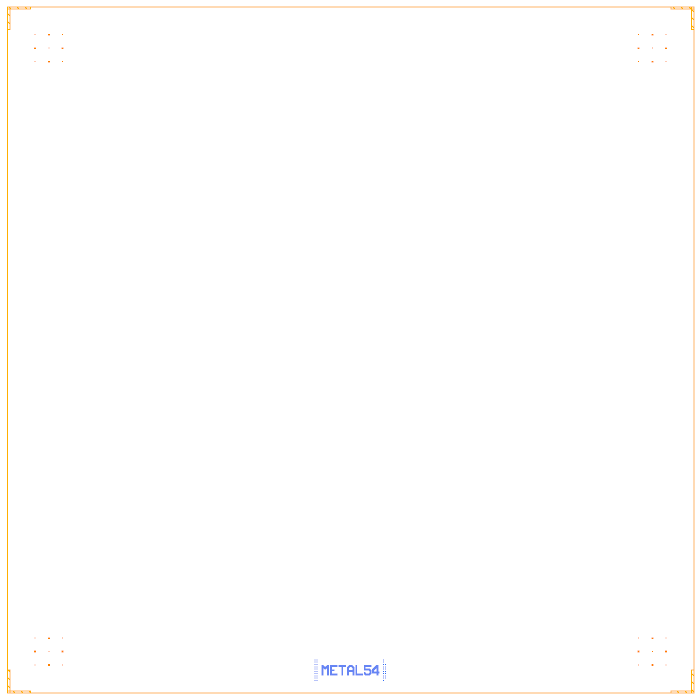

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/m54_wallraff_cell_s1_die.png')

In [5]:
d = Designer("m54_wallraff_cell", box=(-2595.4, -3400, 4904.6, 4100), chip={"name_chip": "Metal54"}, live=LIVE)
layout_step(d, OUT / "m54_wallraff_cell_s1_die.png", size=(700, 700), width=350)

## Design 2 · Bond pads

The source is a meshing cut-out of two qubits and their coupler: no launchpads, so the PDK pad rule (outer etch edge
100 µm from the die edge) has nothing to place; `pads_md(d)` in Design 8 confirms there are none.

## Design 3 · Readout: the line

No feedline, readout pads or tees: the cut-out stops 350 µm beyond the qubits, before any readout structure.

## Design 4 · Qubit placement: the two StarQubits and their grounded pads

**The qubits.** `metal:StarQubit` is Metal's star transmon: a centre island (radius 53 µm) with the junction, and
five pads at 72° — four coupler pads `pin_cpl1`–`pin_cpl4` and a readout pad `pin_rdout` — each in its own gap
(13 / 6 µm). The rotations set where each pad points (the builder's `pad_angles`): D5's `pin_cpl1` faces Z3, Z3's
`pin_cpl3` faces D5.

**The junction.** With `junction_type` unset the wrapper already draws the Quantcore trilayer junction;
`trilayer_junction` makes it explicit and returns the drawn junction's L_J and C_J for the LOM and the FEM junction
port (`junction=`). The source has no junctions (it is an electrostatics study), so both qubits get the PDK nominal
junction (fingers 0.5 × 0.6 µm on 2/0 + 4/0, a 50/0 spacer with the 51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH,
C_J 15 fF).

**The free pads.** The pads without a line (D5: `cpl2`, `cpl3`, `cpl4`, readout; Z3: `cpl1`, `cpl2`, `cpl4`,
readout) end at the pocket edge, so in this cut-out they are ground, as in the source's Elmer model (which merges them
into `ground_plane`). Each gets a `metal:ShortToGround` snapped to its pin (`snap="short", to=<pin>`): no geometry,
it tells the LOM the pad is grounded.

The picture shows the cut-out's own extent, (0, 0)–(2309.2, 700) µm.

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


D5 ports: ['pin_cpl1', 'pin_cpl2', 'pin_cpl3', 'pin_cpl4', 'pin_rdout', 'squid_a', 'squid_b']


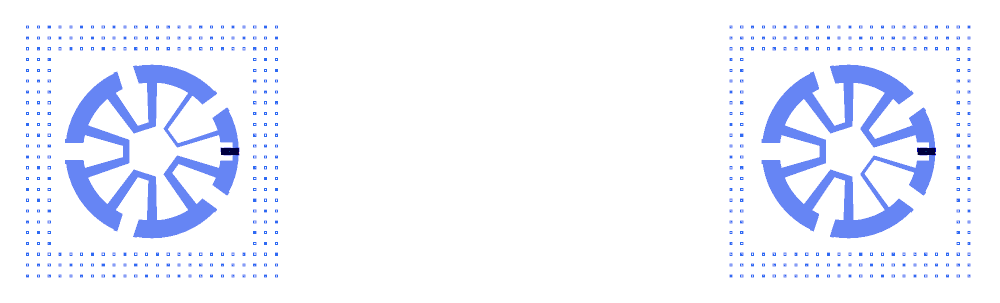

**On the chip so far:** 0 pads · 2 qubits · 8 other components · 0 routes · 0 declared couplings. **This step added** 10 component(s) `D5`, `Z3`, `D5_pin_cpl2_gnd`, `D5_pin_cpl3_gnd`, `D5_pin_cpl4_gnd`, `D5_pin_rdout_gnd`, `Z3_pin_cpl1_gnd`, `Z3_pin_cpl2_gnd` … (+2).

WindowsPath('examples/designs/metal/m54_wallraff_cell_step_parts.png')

In [6]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    q = {n: d.add(n, "metal:StarQubit", at=P(x, 0), junction=JUNCTION, **JJ_PARAMS, **STAR, **ROT[n])
         for n, x in (("D5", 0), ("Z3", 1609.2))}
    # the free pads end at the pocket edge: ground in this cut-out (the source's Elmer model)
    for n, pins in (("D5", ("pin_cpl2", "pin_cpl3", "pin_cpl4", "pin_rdout")),
                    ("Z3", ("pin_cpl1", "pin_cpl2", "pin_cpl4", "pin_rdout"))):
        for pin in pins:
            d.add(f"{n}_{pin}_gnd", "metal:ShortToGround", snap="short", to=getattr(q[n], pin))
print("D5 ports:", sorted(q["D5"].ports))
layout_step(d, OUT / "m54_wallraff_cell_step_parts.png", box=(0, 0, 2309.2, 700), size=(1000, 303), width=500)

## Design 5 · Readout: the resonators

None: the source's readout pads (`pin_rdout`) are grounded in this cut-out (segment 4), as in its Elmer model.

## Design 6 · Coupling: the coupler line

`CPL_D5_Z3` runs from D5's `pin_cpl1` to Z3's `pin_cpl3` through the builder's traced points (the first and last are
the pins themselves, so the interior 29 are the waypoints), on the source's 8.5 / 5.5 µm CPW with its 15 µm fillet.
The route is 1349.7 µm long (from the v1 run; the builder's polyline, 1351.7 µm, less what the 15 µm fillets cut off).

The coupler is a plain `cpw` route (no fixed length), so the router lays it exactly on the waypoints; in the LOM it is
a wire that joins the two coupler pads into one node (LOM 1 says what that misses).

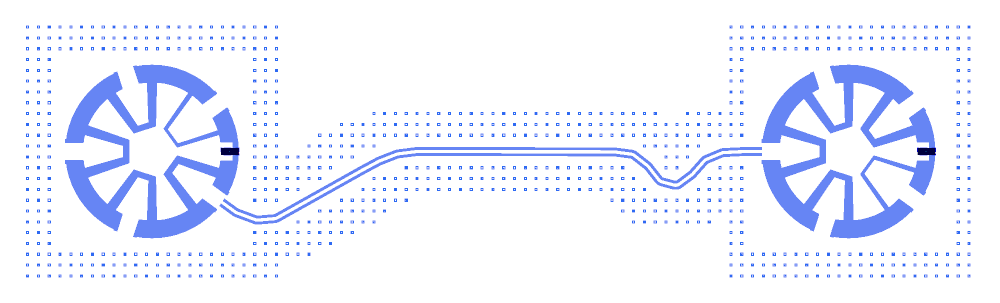

**On the chip so far:** 0 pads · 2 qubits · 8 other components · 1 routes · 0 declared couplings. **This step added** 1 route(s) `CPL_D5_Z3`.

WindowsPath('examples/designs/metal/m54_wallraff_cell_s6_coupler.png')

In [7]:
with d.batch():
    d.route("CPL_D5_Z3", q["D5"].pin_cpl1, q["Z3"].pin_cpl3, a=8.5, b=5.5, r=15, nodes=[P(*p) for p in CPL[1:-1]])
layout_step(d, OUT / "m54_wallraff_cell_s6_coupler.png", box=(0, 0, 2309.2, 700), size=(1000, 303), width=500)

## Design 7 · Routing: control lines

None: the cell has no flux or drive lines.

## Design 8 · The whole chip: sim group, centring, save

**Sim group:** `cell` — both qubits and the coupler, with the box at the cut-out's own extent (margin 0, as in the
source's mesh), for a Q3D C-matrix job.

**Centring.** The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes: here the two stars, radius 160 µm plus their 40 µm connectors, so (150, 150)–(2159.2, 550)
µm) and shifts the design so its centre is the die centre. The die was centred on the cut-out, so nothing moves.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*.

content shifted by (0.0, 0.0) µm; content box (150.0, 150.0, 2159.2, 550.0)


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

**Same design as before:** `examples/designs/metal/m54_wallraff_cell.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer m54_wallraff_cell: 10 instances, 1 routes, live=False> → examples\designs\metal\m54_wallraff_cell.json
route lengths (µm): {'CPL_D5_Z3': 1349.7}


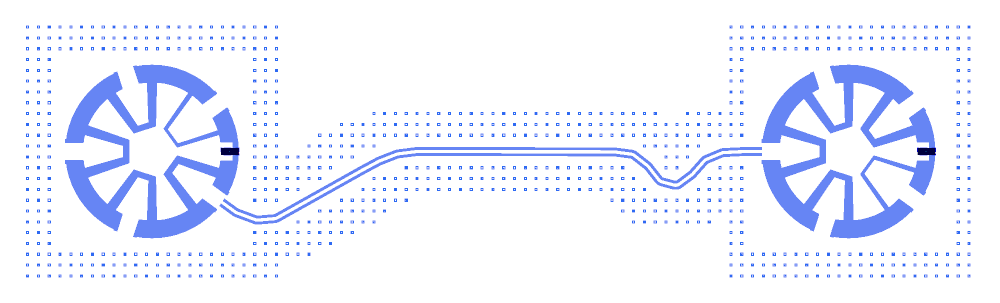

**On the chip so far:** 0 pads · 2 qubits · 8 other components · 1 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/m54_wallraff_cell_step_routes.png')

In [8]:
d.sim_group("cell", ["D5", "Z3", "CPL_D5_Z3"], margin_um=0, analyses=["q3d_cmatrix"])
shift = center_in_die(d)
rebuild(d)
box = content_box(d)
print("content shifted by", shift, "µm; content box", (round(box.left, 1), round(box.bottom, 1), round(box.right, 1),
      round(box.top, 1)))
display(Markdown(pads_md(d)))
DESIGN, same = save_design(d, OUT / "m54_wallraff_cell.json")
display(Markdown(same))
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "m54_wallraff_cell_step_routes.png", box=(0, 0, 2309.2, 700), size=(1000, 303), width=500)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**, four `dangling_port` warnings (`D5` / `Z3` `squid_a` / `squid_b`, the
junction's attachment points: the StarQubit cell draws the junction itself, nothing is routed there) and **no PDK
design warnings** (no pads, the nominal junction is in the R_n window, no targets).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each `StarQubit` gives a grounded centre island with its junction
and a node per pad (C to the island and to ground); the two coupler pads joined by `CPL_D5_Z3` are one node (the
coupler, a 1.35 mm open–open line, far above the qubits); the free pads are ground through their `ShortToGround`s.
The port map shows where each of D5's ports landed.

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith("D5.")})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation and the source's Elmer capacitances

The capacitances the LOM estimates against the source's ElmerFEM matrix, then the two qubits with the coupler, once
from the LOM estimates and once from the source's Elmer matrix (free pads in ground, the PDK junctions).

- The StarQubit model is rough: its C_Σ is well below Elmer's 167 fF (the star arms are neglected), and C(island,
  coupler) a little below Elmer's 18.4 fF.
- **The LOM coupler is too light:** a `cpw` route between two pads is a wire, so the coupler node has only the two
  pads' capacitance to ground instead of Elmer's 382 fF (the 1.35 mm line alone is ≈ 195 fF). Reported; the LOM mode splitting is therefore not a result.
- From the Elmer matrix (C_Σ 167 / 168 fF, E_C ≈ 116 MHz) with the PDK 6.73 nH both qubits sit near 4.6 GHz (v1 run); they are
  nearly degenerate, so the two modes are mixed and a per-pair ZZ is not defined.

In [ ]:
def c_sum(model, node, other=None):
    """Sum of the C branch estimates between ``node`` and ``other`` (any node if None), fF."""
    tot = 0.0
    for b in model.branches.values():
        if b.type == "C" and node in b.nodes and (other is None or other in b.nodes):
            tot += b.value["estimate"]
    return tot

cpl = next(n for n in lb.model.nodes if n.startswith("D5.pin_cpl1"))   # the coupler net
rows = ["| quantity | LOM estimate (fF) | Elmer, source (fF) |", "|---|---|---|"]
for n in ("D5", "Z3"):
    rows.append(f"| C_Σ {n} | {c_sum(lb.model, n):.1f} | {ELMER[n]} |")
    rows.append(f"| C({n}, coupler) | {c_sum(lb.model, n, cpl):.2f} | {ELMER[n + '-cpl']} |")
display(Markdown("\n".join(rows)))
res = simulate_groups(d, {"cell": ["D5", "Z3", "CPL_D5_Z3"]}, max_modes=3)
display(Markdown("**D5–coupler–Z3 from the LOM estimates, QuCat normal modes:**\n\n" + modes_md(res["cell"])))

# the same circuit from the source's Elmer C-matrix (free pads in ground), with the PDK junctions
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.circuit.schema import CircuitModel
C = lambda a, b, v: {"type": "C", "nodes": [a, b], "value": {"estimate": v}}
JJ = lambda n: {"type": "JJ", "nodes": [n, "gnd"], "value": dict(JUNCTION)}
elmer_model = CircuitModel.model_validate({"name": "m54_elmer", "nodes": {"gnd": {"ground": True}, "D5": {}, "Z3": {}, "cpl": {}},
    "branches": {"C_D5": C("D5", "gnd", ELMER["D5"] - ELMER["D5-cpl"] - ELMER["D5-Z3"]),
                 "C_Z3": C("Z3", "gnd", ELMER["Z3"] - ELMER["Z3-cpl"] - ELMER["D5-Z3"]),
                 "C_cpl": C("cpl", "gnd", 381.59), "Cg_D5": C("D5", "cpl", ELMER["D5-cpl"]),
                 "Cg_Z3": C("Z3", "cpl", ELMER["Z3-cpl"]), "C_D5_Z3": C("D5", "Z3", ELMER["D5-Z3"]),
                 "J_D5": JJ("D5"), "J_Z3": JJ("Z3")}})
res_elmer = {"cell (Elmer C)": simulate(fill(elmer_model, None), max_modes=2)}
display(Markdown("**D5–coupler–Z3 from the source's Elmer C-matrix, QuCat normal modes:**\n\n" + modes_md(res_elmer["cell (Elmer C)"])))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(res | res_elmer)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) the normal modes of the cell from the LOM estimates and from the source's Elmer
matrix (QuCat; circles are qubits, squares the coupler if it has a mode; filled markers are the QuTiP dressed
values), (b) the dispersive shift of any resonator (none here: the panel says so). Here (from the v1 run) the LOM
puts the qubits ≈ 2 GHz above the Elmer circuit: its StarQubit C_Σ is too small (LOM 1).

In [ ]:
plot_lom({**res, **res_elmer}, OUT / "m54_wallraff_cell_lom.png", title="m54: LOM estimates vs the source's Elmer C")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here D5's centre island, `center_radius` 53 → 70 µm (the pins stay where they are, so the
coupler line still fits) — rebuild, re-run the LOM of the cell and compare. A bigger island adds to D5's C_Σ: D5 moves
down and away from Z3, so the two qubits un-mix.

In [ ]:
d2 = design_copy(DESIGN)
d2["D5"].set(center_radius=70)                   # 53 → 70 µm
after = simulate_groups(d2, {"cell": ["D5", "Z3", "CPL_D5_Z3"]}, max_modes=3)
display(Markdown(params_delta_md(res, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

One Q3D C-matrix job for the group `cell`, with the box at the chip's own extent (margin 0, as in the source's
mesh). Its nets are the LOM's nodes, so after a solve it gives the matrix the source got from Elmer. In the v1 run the
exporter named both islands (`D5.island`, `Z3.island`) but still printed "Unable to create polygon for port 1 / 2"
for the StarQubit junction ports, and the coupler line is a waveguide port pair, not a named net (an exporter limit
for this cell, reported before the rebuild).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix of the sim group `cell`
display(Markdown(jobs_md(jobs)))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of the cell `cell` (the two islands as named nets; the coupler line ends as a waveguide port pair,
see Simulate 1): the matrix the source got from ElmerFEM. `fem_stage` solves the job with `RUN_FEM`, else loads its
kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

Not exported here. An eigenmode job needs each junction as a lumped L_J sheet on its junction port, and in the v1 run
the export could not draw a port polygon for a StarQubit junction (the warning in Simulate 1), so the solve would
miss a junction. Once the export draws both junction ports, `export_sims(DESIGN, ["cell"], analysis="eigenmode_epr")`
is the call (an existing group, so the design stays the same) and gives the two qubit modes and their pyEPR values.

## Simulate 4 · Full-wave (driven) run

Nothing to drive: the cut-out has no readout resonator and no port of its own.

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step. Without an eigenmode job there are no FEM modes to plot or read (**Results 1–2** stay
empty for this cell); the comparison with the LOM uses the C-matrices: the source's Elmer matrix, and the Q3D job
once it is solved.

## Results 3 · FEM against the LOM

The qubit frequencies and anharmonicities of the LOM (on its own estimates, LOM 1) next to the same circuit on the
source's Elmer C-matrix (LOM 1, always there) and, when the Q3D job of `cell` is kept (Simulate 2), next to the LOM
filled with it (`fill`: the C-matrix values replace the estimates by net name), with the difference in %.

In [ ]:
from quantcore_circuits.circuit.fill import fill

keys = ["D5.f_q_GHz", "D5.alpha_MHz", "Z3.f_q_GHz", "Z3.alpha_MHz"]
est, elmer = res["cell"].params, res_elmer["cell (Elmer C)"].params
rows = [(k, est.get(k), elmer.get(k), "the source's Elmer C-matrix") for k in keys]
if keep_q3d.get("cell"):
    on_fem = simulate(fill(d.lom(select=["D5", "Z3", "CPL_D5_Z3"]).model, DESIGN, keep_q3d["cell"]), max_modes=3).params
    rows += [(k, est.get(k), on_fem.get(k), "LOM on the Q3D C-matrix") for k in keys]
display(Markdown(fem_vs_lom_md(rows)))

## Results 4 · Feedback: one step towards a target

The source states no targets; its two qubits are nearly degenerate, so their modes mix (LOM 1). This notebook sets
one target as an exercise that un-mixes them: **D5 at 4.35 GHz** in the source's Elmer-matrix circuit, ≈ 0.2 GHz below
its mode there (from the v1 run: QuCat 4.56 GHz, mixed 76 / 24 % with Z3's 4.54 GHz). The Elmer matrix is this cell's
FEM, so the feedback runs on it rather than on the LOM estimates (2 GHz off, LOM 2).

`loop.feedback` tunes qubit–readout pairs, and this cell has none (the coupler is a wire between two pads), so the
step is a first-order rule in the notebook: for a transmon f_q ∝ 1/√L_J, so **L_J ← L_J · (f_now / f_target)²**, kept
inside the PDK window (`pdk_lj_bounds`: R_n 40–50 kΩ). By the transmon formula the target needs L_J ≈ 7.2–7.3 nH
(R_n ≈ 48–49 kΩ). Each new L_J is drawn as a trilayer junction (`trilayer_junction(..., lj_nH=...)`, which gives its
C_J too) and the Elmer circuit is solved again with it. The table shows one step.

In [ ]:
Q_T, F_T, TOL = "D5", 4.35, 0.020                # the exercise target: D5 at 4.35 GHz ± 20 MHz (Elmer circuit)
LO, HI = pdk_lj_bounds(DESIGN)[f"{Q_T}.junction.Lj_nH"]   # the PDK R_n window as L_J bounds (nH)


def elmer_f(lj_nH):
    """D5's dressed f_q (GHz) in the source's Elmer-matrix circuit (LOM 1) with D5's junction drawn for lj_nH;
    returns (f_q, junction params, junction values)."""
    jp, jj = trilayer_junction("metal:TransmonPocket", lj_nH=lj_nH)
    m = elmer_model.model_copy(deep=True)
    m.branches["J_D5"].value = dict(jj)
    return simulate(fill(m, None), max_modes=2).params.get(f"{Q_T}.f_q_GHz"), jp, jj


def lj_step(lj_now, f_now):
    """The feedback rule: f_q ∝ 1/√L_J to first order, so L_J ← L_J · (f_now / F_T)², inside the PDK window."""
    return min(max(lj_now * (f_now / F_T) ** 2, LO), HI)


lj0, f0 = JUNCTION["Lj_nH"], res_elmer["cell (Elmer C)"].params.get(f"{Q_T}.f_q_GHz")
f1, jp1, jj1 = elmer_f(lj_step(lj0, f0))
display(Markdown(before_after_md({"D5 L_J (nH)": lj0, "D5 f_q (GHz)": f0}, {"D5 L_J (nH)": jj1["Lj_nH"], "D5 f_q (GHz)": f1})))
print(f"target {F_T} ± {TOL} GHz; one step leaves {1e3 * (f1 - F_T):+.1f} MHz")

## Results 5 · Iterate to the target

The feedback step, repeated: solve the Elmer circuit with the new L_J → on target (± 20 MHz)? → else the rule again,
until on target or `MAX_ITER` steps. The rule is first order (f_q = √(8 E_J E_C) − E_C, not ∝ 1/√L_J), so the first
step falls a little short and the next ones close the gap. The last L_J is then written into a copy of the design
(`design_copy`: D5's junction drawn for it; `build/m54_wallraff_cell_target/`), which is DRC-checked. The table shows
each iteration (on: FEM = the source's Elmer matrix), the plot the residual in tolerances (on target below 1). With a
kept Q3D job of `cell` the same loop can run on the design's own C-matrix: replace `elmer_f` by the LOM filled with it
(Results 3).

In [ ]:
from quantcore_circuits.assembly.drc import check

history, lj, f, jp, jj = [], lj0, f0, None, None
for k in range(MAX_ITER + 1):
    r = None if f is None else (f - F_T) / TOL
    entry = {"iteration": k, "design": Path(DESIGN.name if k == 0 else f"rev{k}"), "fem": True,
             "objective": None if r is None else abs(r), "values": {f"{Q_T}.f_q_GHz": f},
             "targets": {f"{Q_T}.f_q_GHz": (F_T, TOL)}, "on_target": r is not None and abs(r) <= 1, "knobs": {},
             "notes": []}
    history.append(entry)
    if entry["on_target"] or r is None or k == MAX_ITER:
        break
    lj_new = lj_step(lj, f)
    if lj_new in (LO, HI):
        entry["notes"].append("L_J at the edge of the PDK window")
    f, jp, jj = elmer_f(lj_new)
    entry["knobs"] = {f"{Q_T}.junction.Lj_nH": (lj, jj["Lj_nH"])}
    lj = jj["Lj_nH"]
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "m54_wallraff_cell_iterate.png")
if jj is not None:                               # the last step's junction, drawn in a copy of the design
    d_t = design_copy(DESIGN, "_target")
    d_t[Q_T].set(junction=jj, **jp)
    rev = d_t.save(Path("build") / "m54_wallraff_cell_target" / f"rev{history[-1]['iteration']}.json")
    print("last design:", rev, "· D5 L_J", jj["Lj_nH"], "nH · DRC:", "clean" if check(str(rev)).ok else "ERRORS",
          "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** Notebook 54 never exports a GDS (it meshes the cut-out with gmsh), so the original has no
cheese: the PDK band applies (`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer
(5 µm squares, 20 µm gaps, three rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full die; the cell (compare the source's `qm.view` figure); D5 with its five pads and the coupler leaving at
324°; Z3; D5's trilayer junction; the **fab mask** round D5 (1/0 etch with the PDK cheese band, the 3/0 keep-out, the
junction layers); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on 1001/0). Positions are
read from the design.

In [ ]:
dx, dy = d.data["instances"]["D5"]["place"]["at"]
zx, zy = d.data["instances"]["Z3"]["place"]["at"]
show_snapshot(d, OUT / "m54_wallraff_cell.png", size=(1400, 1400))
show_snapshot(d, OUT / "m54_wallraff_cell_cell.png", box=(dx - 350, dy - 350, zx + 350, zy + 350), size=(1600, 485))
show_snapshot(d, OUT / "m54_wallraff_cell_d5.png", box=(dx - 240, dy - 240, dx + 240, dy + 240), width=420)
show_snapshot(d, OUT / "m54_wallraff_cell_z3.png", box=(zx - 240, zy - 240, zx + 240, zy + 240), width=420)
show_snapshot(d, OUT / "m54_wallraff_cell_jj.png", box=(dx - 100, dy - 100, dx + 100, dy + 100), width=300)
snap_file(Path("build") / "m54_wallraff_cell_fab.oas", OUT / "m54_wallraff_cell_cheese.png",
          box=(dx - 300, dy - 300, dx + 300, dy + 300), size=(1200, 1200), width=420)
show_snapshot(d, OUT / "m54_wallraff_cell_frame.png", box=(-2595.4, -3400, -1695.4, -2500), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | both StarQubits with the builder's options and pad rotations, their positions, the traced coupler line (31 points, 8.5 / 5.5 µm, fillet 15 µm), the cut-out's extent and the margin-0 sim box |
| PDK changes | the 7.5 mm Quantcore die with the QCT frame round the cut-out; sapphire stack; trilayer junctions (PDK nominal); PDK cheese band; content centred (no shift needed); no pads to place |
| differs | junctions where the source has none; the free pads are grounded through `ShortToGround`s, not merged into the ground metal |
| LOM (from the v1 run) | LOM estimates: C_Σ 104 fF (Elmer 167 fF), C(island, coupler) 15.0 fF (Elmer 18.4 fF); D5 / Z3 6.40 / 6.72 GHz dressed (QuCat 6.64 / 6.97, fully mixed through the too-light coupler node); from the source's Elmer C-matrix 4.54 / 4.56 GHz, mixed 76 / 24 %; iterate (D5 `center_radius` 53 → 70 µm): D5 −413 MHz, Z3 −125 MHz |
| PDK design warnings | none |
| layout | built in segments (die, the two StarQubits with their grounded pads, the coupler line, the whole chip; no pads, readouts or control lines); the saved JSON is the v1 notebook's |
| feedback | an exercise target (D5 4.35 GHz, un-mixing the pair) by a first-order L_J rule on the source's Elmer-matrix circuit (no qubit–readout pair for `loop.feedback`); the last L_J drawn in a design copy |
| open | the LOM StarQubit / coupler-line models (lom requests); the Q3D job is exported, not solved (`RUN_FEM = False`); no eigenmode job until the export draws the StarQubit junction ports |